# Question 1

Case                 : Q1_caseA
Consumer             : C_01_A
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : 1.43
Min daily energy     : None
Reference profile    : no
Disutility lin/quad  : None / None
Battery              : no
Next-day forecasts   : yes
status: OPTIMAL | objective: -2.61 DKK
daily totals (kWh): import=12.0, export=3.0, load=35.9, pv=26.9


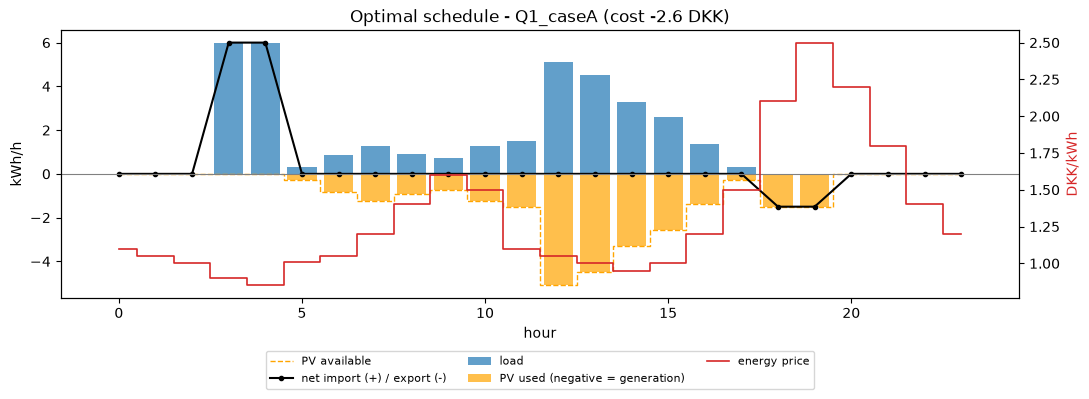

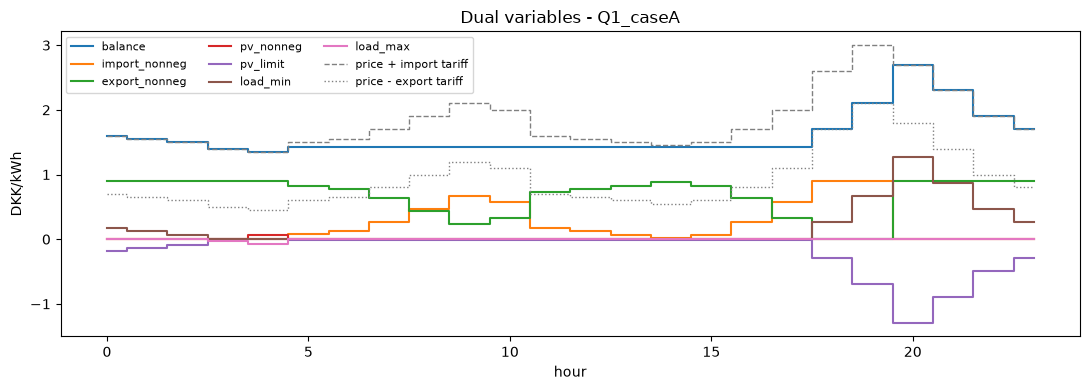

In [5]:
from src.data_loader import load_question
from src.model import FlexibleConsumerModel
from src.plotting import plot_schedule, plot_duals
from src.scenarios import scale_prices

data = load_question("Q1_caseA")
print(data.summary())

results = FlexibleConsumerModel(data).build().solve()
print(results)                    # objective, daily totals, scalar duals
results.hourly                    # DataFrame: one row per hour with variables, prices and hourly duals
plot_schedule(results, data)

plot_duals(results, data)

high_spread = scale_prices(data, factor=2.0, keep_mean=True)
results_hs = FlexibleConsumerModel(high_spread).build().solve()